# Case Study 8 — Detecting Mule Bank Accounts: Imbalanced Classification, Class Weights, PR Curves and Action Tiers

**Priority:** ★★★ Must-visit · **Reference:** Case Study 8 — *Paytm Payments Bank: Detecting Mule Bank Accounts with a Class-Weighted Random Forest* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Financial Crime / AML, Fraud Operations, Compliance (Principal Officer), Risk Committee
**Data:** ⚠️ **SYNTHETIC** (D-8-01). Account-level AML labels are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs08_mule_account_detection.ipynb`

## 0. Executive Summary for Business

*(Synthetic data calibrated to Paytm Payments Bank's documented problem; written after the analysis.)*

- **The problem:** mule accounts (fewer than 1 in 100) carry stolen money onward. Today's rules catch **42%** of mules, and **87% of their alerts are innocent customers**, many of them busy traders and students who also move money quickly.
- **"Accuracy" is the wrong yardstick:** a system that flags nobody is 99.2% accurate and catches zero mules. We judge everything on precision, recall and the precision–recall curve.
- **The model:** a Random Forest that counts each mule as 5 genuine accounts (the documented 1:5 weighting), on **17 pruned signals** (account age, pass-through speed, merchant spending, ATM use, shared devices…). It reaches **62% precision and 65% recall** (documented production: 65% / 74%), against 13% / 42% for the rules. Both gains are highly significant.
- **The documented choices hold up:** the 1:5 weighting beat no weighting, full balancing, logistic regression, an RF regressor and gradient boosting (every difference significant). Pruning from 45 to 17 features cost only 0.012 PR-AUC (about 2%), a deliberate trade for real-time speed.
- **Tiered action:** the **block tier is 92% precise** (234 of 255 accounts are mules). The investigate tier (41% precise) holds another quarter of the mules. Investigations fall from about 26,000 to 5,100 a month per 10 lakh accounts, **within team capacity**, while stopping **57% more mules**.
- **₹ impact:** ≈ **₹11 crore a month more fraud proceeds intercepted net of costs per 10 lakh accounts** (range ₹6–16 crore). Genuine customers actioned fall by **85%** (22,600 → 3,300).
- **I recommend:** deploy RF 1:5 with block / investigate / watch tiers; use isotonic-calibrated scores for capacity planning; give rented and cash-out mules (57% and 56% recall) priority in the next feature round.

## 1. The Problem in Simple English

When a scammer tricks someone into sending ₹50,000, the money does not go to the scammer's own account. It lands in a **mule account**: a bank account opened, rented or bought for the purpose. Within an hour it is split and passed on, or withdrawn in cash from ATMs in three different towns. Mule accounts are the plumbing of almost every digital fraud. The reference file notes that RBI found mules behind "53% of the total fraud threats" (Case 9).

Finding them is a **needle-in-a-haystack** problem. Fewer than 1 in 100 accounts is a mule, and many genuine customers (small traders, gig workers, students receiving money from home) also receive many payments and spend them quickly. Today's rule system finds about half of the mules, but four in five of its alerts are innocent customers, which wastes investigators' time and angers good customers whose accounts are frozen.

The bank wants:
1. a model that finds **more mules with fewer false alarms**, judged with the right metrics (not "accuracy");
2. a **small, robust set of signals** that can be computed in real time;
3. a way to turn scores into **actions**: block immediately, restrict and investigate, or just watch.

## 2. Reference from the Case File

### (a) What Paytm Payments Bank did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Mule accounts receive and pass on fraud proceeds. The existing detection had 'roughly **20% precision and 50% recall**'." |
| Question | "Can ML raise recall without losing precision, so the bank can **tier its response**: investigate or limit uncertain accounts, and block high-confidence ones immediately?" |
| Data | Account data + transaction data; "1.5M accounts train; 700K accounts validation"; exact features ND |
| Approach | Feature engineering with the India Fraud Prevention team → "significant feature pruning" down to **17 features** → algorithm comparison → class weighting → hold-out validation → real-time deployment with a rule engine |
| Statistics | "PR curves and ROC curves were used for threshold selection. Formal tests: ND." |
| ML | "Random Forest Regressor, Gradient Boosting Classifier and neural networks were tested. **Random Forest Classifier** was chosen." "**Class weighting 1:5** (non-mule : mule)." Hold-out of 700K accounts. Metrics: precision, recall, PR and ROC curves |
| Tools | **Maquette** (Paytm Labs real-time risk platform) + rule engine |
| Decision | "High scores lead to immediate blocking; medium scores lead to investigation or limits." |
| Impact | "Production precision **65.1%** and recall **74.1%**, against a baseline of about 20% precision and 50% recall." |

**Source:** Paytm Labs blog (mule account detection post, undated) — https://paytmlabs.com/blog/

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 220,000 accounts (150k train / 70k validation, 1/10 of the documented scale); mule rate ≈ 0.83%; three mule typologies with random intensity; 15% of genuine customers are "busy traders" (hard negatives); 39 candidate features, including redundant and pure-noise ones |
| Baseline | A realistic AML rule set ("any of three red flags") |
| Pruning | Statistical screening (Mann–Whitney/chi-square + Holm) → redundancy removal (Spearman clusters) → permutation-importance backward elimination to **17 features**, with a bootstrap check that performance does not drop |
| Models | Logistic, RF regressor, gradient boosting, RF unweighted, **RF 1:5 (documented)**, RF fully balanced; PR-AUC with bootstrap CIs; paired comparisons |
| Decisions | PR-curve tier thresholds (block / investigate / watch), calibration check, recall by mule type, investigator-capacity economics |

### (c) How the industry uses this

Every Indian bank and payments bank runs mule detection under RBI's fraud-risk directions and PMLA obligations, and reports to FIU-IND. RBIH's MuleHunter.AI (Case 9) offers a shared model to 26+ banks. The same imbalanced-classification toolkit (class weights, PR curves, threshold tiers) is used for card fraud, insurance-claim fraud and loan-application fraud.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can we replace (or augment) the rule system with a model that catches more mules at higher precision, with tiered actions? |
| Analytical 1 | Which account and behaviour signals separate mules from genuine customers, including hard-to-separate busy traders? |
| Analytical 2 | Can we prune to ~17 robust features without losing performance? |
| Analytical 3 | Which algorithm and class weight give the best precision–recall trade-off on held-out accounts? |
| Analytical 4 | At the chosen thresholds, are precision and recall significantly better than the rules? |

**Hypotheses**
- **H1:** H0: each feature has the same distribution for mules and genuine accounts (Mann–Whitney / chi-square, Holm).
- **H2:** H0: PR-AUC with 17 features = PR-AUC with all features (paired bootstrap; we *want* to fail to reject).
- **H3:** H0: RF 1:5 and each alternative have equal PR-AUC (paired bootstrap of the difference).
- **H4:** H0: model precision = rule precision (two-proportion Z); H0: the model and rules detect the same mules (McNemar).

**Primary metric:** **precision and recall at the operating threshold**, compared with the documented baseline (~20% / 50%) and target (65% / 74%). **Ranking metric:** PR-AUC (average precision), not accuracy and not ROC-AUC. **Guardrails:** genuine accounts restricted per 10,000; recall per mule typology; investigator workload ≤ capacity.
**Unit:** account. **Decision rule:** deploy if precision and recall both beat the rules significantly (p < 0.05) and the block tier's precision is ≥ 85% (wrongly freezing a genuine account is a serious harm).

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve, brier_score_loss
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public mule / AML account-level datasets (UCI, data.gov.in, GitHub) | **None with real labels.** Public AML sets on GitHub (e.g., IBM's synthetic AMLworld transactions) are US-style wire transfers without Indian account/KYC/UPI features. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | Synthetic account-level data with typologies, hard negatives and junk features (D-8-01). |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs08.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 8 (Paytm-style mule account detection)
============================================================================
THIS DATA IS SYNTHETIC. Bank account-level AML labels are confidential.

220,000 accounts (train 150k / validation 70k, mirroring the documented 1.5M / 700K split at
1/10 scale) with ~40 candidate account and 30-day transaction-behaviour features and a mule label.
Realism built in:
  * three mule typologies - purpose-made new accounts, rented/sold aged accounts (students),
    cash-out mules (ATM heavy) - each with a random INTENSITY (many mules are lightly used)
  * 15% of genuine customers are "busy traders / gig workers" whose volumes and pass-through
    look mule-like (hard negatives)
  * redundant and pure-noise candidate features, so pruning (documented: down to 17) matters
Calibration anchors (reference file, Case Study 8): imbalanced binary target; existing detection
"roughly 20% precision and 50% recall"; class weighting 1:5; Random Forest chosen; tiered response.
Rates and effect sizes are our assumptions (decision.md D-8-02, D-8-03).

Output: data/cs08/accounts.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
N = 220_000
MULE_RATE = 0.008


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    mule = rng.random(N) < MULE_RATE
    typ = np.where(mule, rng.choice(["purpose_made", "rented", "cash_out"], N, p=[0.40, 0.40, 0.20]), "genuine")
    pm, rt, co = typ == "purpose_made", typ == "rented", typ == "cash_out"
    u = np.where(mule, rng.beta(2, 2, N), 0.0)                                  # mule intensity 0..1
    trader = (~mule) & (rng.random(N) < 0.15)                                   # hard negatives
    student = rng.random(N) < np.where(rt, 0.6, 0.08)
    age_days = np.where(pm, np.exp(rng.normal(np.log(60), 0.9, N)), np.exp(rng.normal(np.log(700), 0.9, N)))
    in_cnt = rng.poisson(np.exp(rng.normal(np.log(9) + 1.2 * u + 0.9 * trader, 0.8, N)))
    in_snd = rng.binomial(in_cnt, np.clip(0.35 + 0.30 * u + 0.20 * trader, 0, 0.95))
    out_cnt = rng.poisson(np.exp(rng.normal(np.log(14) + 0.8 * u + 0.6 * trader, 0.6, N)))
    avg_in = np.exp(rng.normal(np.log(2500) + 0.6 * u, 0.9, N))
    pass_a = np.where(trader, 12, 6 + 14 * u); pass_b = np.where(trader, 2, 3 - 1.5 * u)
    df = pd.DataFrame({
        "account_id": [f"A{i:07d}" for i in range(1, N + 1)],
        "account_age_days": np.clip(age_days, 3, 4000).round(),
        "kyc_type": np.where(rng.random(N) < 0.15 + 0.30 * pm, "min-KYC", "full-KYC"),
        "holder_age": np.clip(np.round(np.where(student, rng.normal(21, 2, N), rng.normal(36, 11, N))), 18, 85),
        "occupation": np.where(student, "student", rng.choice(["salaried", "self-employed", "homemaker", "retired", "other"], N, p=[0.45, 0.25, 0.12, 0.08, 0.10])),
        "pincode_risk_tier": rng.choice(["low", "medium", "high"], N, p=[0.6, 0.3, 0.1]),
        "devices_linked_30d": rng.poisson(0.1 + 0.8 * u) + 1,
        "accounts_sharing_device": rng.poisson(0.15 + 0.5 * u + 1.5 * u * pm),
        "inbound_txn_30d": in_cnt,
        "inbound_distinct_senders_30d": in_snd,
        "inbound_count_7d": rng.binomial(in_cnt, 0.3),                                 # redundant with the 30-day count
        "outbound_txn_30d": out_cnt,
        "distinct_beneficiaries_30d": np.minimum(out_cnt, rng.poisson(out_cnt * (0.3 + 0.2 * u) + 1)),
        "avg_inbound_amount": np.round(avg_in, 0),
        "total_inflow_30d": np.round(in_cnt * avg_in, 0),                               # redundant
        "max_single_inbound": np.round(avg_in * np.exp(rng.gamma(2, 0.5, N)), 0),
        "pass_through_ratio": np.round(rng.beta(pass_a, pass_b), 3),
        "median_dwell_minutes": np.round(np.exp(rng.normal(np.log(4000) - 2.5 * u - 1.2 * trader, 1.2, N)), 0),
        "round_amount_share": np.round(rng.beta(2 + 2 * u, 5), 3),
        "night_txn_share": np.round(rng.beta(1.5 + 1.2 * u, 10 - 4 * u), 3),
        "atm_withdrawal_share": np.round(np.where(co, rng.beta(2 + 4 * u, 4), rng.beta(1.2, 8, N)), 3),
        "atm_distinct_locations_30d": rng.poisson(1 + 3 * co * u),
        "merchant_spend_share": np.round(rng.beta(4 - 2.5 * u, 4 + 3 * u), 3),
        "bill_payments_30d": rng.poisson(2.5 - 1.8 * u),
        "salary_like_credit": (rng.random(N) < np.where(trader, 0.20, 0.42 - 0.30 * u)).astype(int),
        "dormant_then_active": (rng.random(N) < np.where(rt, 0.40, 0.03)).astype(int),
        "upi_handle_changes_90d": rng.poisson(0.15 + 0.5 * u),
        "inbound_from_flagged_accounts": rng.poisson(0.03 + 0.45 * u),
        "avg_balance": np.round(np.exp(rng.normal(np.log(18000) - 1.8 * u - 0.7 * trader, 1.2, N)), 0),
        "max_daily_inflow_ratio": np.round(np.exp(rng.normal(0.8 + 0.6 * u, 0.5, N)), 2),
        "email_disposable": (rng.random(N) < 0.03 + 0.15 * pm * u).astype(int),
        "app_logins_30d": rng.poisson(18 + 6 * u),
        "profile_updates_30d": rng.poisson(0.3 + 0.4 * u),
        "failed_login_attempts_30d": rng.poisson(0.6 + 0.5 * u),
        "card_present_txn_30d": rng.poisson(4 - 3 * u),
    })
    for j in range(1, 6):                                                          # pure-noise candidates
        df[f"noise_feature_{j}"] = np.round(rng.normal(0, 1, N), 3)
    df["is_mule"] = mule.astype(int); df["mule_type"] = typ
    df["split"] = np.where(rng.random(N) < 150_000 / N, "train", "validation")
    # ---- data-quality issues ----
    df.loc[df.sample(frac=0.02, random_state=seed).index, "median_dwell_minutes"] = np.nan    # no outflow in window
    df.loc[df.sample(n=40, random_state=seed + 1).index, "holder_age"] = 0                    # KYC parse failure
    df.loc[df.sample(n=25, random_state=seed + 2).index, "pass_through_ratio"] = 1.7          # >1 impossible (reversal double count)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs08"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs08", "accounts.csv.gz"), index=False)
    print(len(d), round(d.is_mule.mean(), 4), d.mule_type.value_counts().to_dict())

Overwriting data/generate_cs08.py


In [3]:
os.makedirs("data/cs08", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs08 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs08/accounts.csv.gz", index=False)
print(f"{len(raw):,} accounts | mule rate {raw.is_mule.mean():.2%} | typologies {raw.mule_type.value_counts().to_dict()}")
raw.groupby("split").is_mule.agg(["size", "sum", "mean"])

220,000 accounts | mule rate 0.83% | typologies {'genuine': 218171, 'rented': 757, 'purpose_made': 700, 'cash_out': 372}


,size,sum,mean
split,,,
train,150261,1246,0.0083
validation,69739,583,0.0084


| Parameter | Value | Basis |
|---|---|---|
| Scale / split | 220k accounts, 150k train / 70k validation | **Documented** 1.5M / 700K, scaled 1/10 |
| Mule rate | ≈ 0.8% | Our assumption (a rare class) |
| Typologies | purpose-made (40%: new, min-KYC, shared devices), rented/sold (40%: aged accounts, students, dormant-then-active), cash-out (20%: ATM-heavy, many locations) | Our assumption, consistent with RBI/RBIH public descriptions of mule patterns |
| Intensity | each mule has u ~ Beta(2, 2): many are lightly used | Our assumption; makes detection realistically hard |
| Hard negatives | 15% of genuine customers are busy traders / gig workers (high inbound, high pass-through, short dwell) | Our assumption, the main source of false positives |
| Junk features | redundant (7-day vs 30-day counts, total = count × average) and 5 pure-noise features | Built in to make the documented pruning meaningful |
| DQ defects | 2% dwell time missing (no outflow); 40 holder ages = 0 (KYC parse failure); 25 pass-through ratios > 1 (reversal double count) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
FEATS_ALL = [c for c in raw.columns if c not in ("account_id", "is_mule", "mule_type", "split")]
fam = {"account_age_days": "account", "kyc_type": "account", "holder_age": "account", "occupation": "account", "pincode_risk_tier": "account",
       "devices_linked_30d": "device", "accounts_sharing_device": "device", "email_disposable": "account", "app_logins_30d": "device",
       "profile_updates_30d": "device", "failed_login_attempts_30d": "device"}
dd = pd.DataFrame({"feature": FEATS_ALL, "family": [fam.get(f, "noise (pure random)" if f.startswith("noise") else "transaction behaviour (30 days)") for f in FEATS_ALL]})
dd.to_csv("data/cs08/data_dictionary.csv", index=False)
print(dd.family.value_counts().to_string()); dd.head(12)

family
transaction behaviour (30 days)    23
account                             6
device                              5
noise (pure random)                 5


,feature,family
0,account_age_days,account
1,kyc_type,account
2,holder_age,account
3,occupation,account
4,pincode_risk_tier,account
5,devices_linked_30d,device
6,accounts_sharing_device,device
7,inbound_txn_30d,transaction behaviour (30 days)
8,inbound_distinct_senders_30d,transaction behaviour (30 days)
9,inbound_count_7d,transaction behaviour (30 days)


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs08/accounts.csv.gz")
checks = {"duplicate account_id": int(df.account_id.duplicated().sum()),
          "holder_age = 0 (KYC parse failure)": int((df.holder_age == 0).sum()),
          "pass_through_ratio > 1 (impossible)": int((df.pass_through_ratio > 1).sum()),
          "median_dwell_minutes missing": int(df.median_dwell_minutes.isna().sum()),
          "inbound distinct senders > inbound count": int((df.inbound_distinct_senders_30d > df.inbound_txn_30d).sum()),
          "negative balances": int((df.avg_balance < 0).sum())}
print(pd.Series(checks, name="rows").to_string())
no_out = df.median_dwell_minutes.isna()
print(f"\nDwell missing rows: mean outbound txns = {df.loc[no_out, 'outbound_txn_30d'].mean():.1f} vs {df.loc[~no_out, 'outbound_txn_30d'].mean():.1f} otherwise; mule rate {df.loc[no_out, 'is_mule'].mean():.2%} vs {df.is_mule.mean():.2%}")

duplicate account_id                           0
holder_age = 0 (KYC parse failure)            40
pass_through_ratio > 1 (impossible)           25
median_dwell_minutes missing                4400
inbound distinct senders > inbound count       0
negative balances                              0

Dwell missing rows: mean outbound txns = 18.9 vs 18.9 otherwise; mule rate 0.82% vs 0.83%


In [6]:
df.loc[df.holder_age == 0, "holder_age"] = np.nan
df["holder_age"] = df.holder_age.fillna(df.loc[df.split == "train", "holder_age"].median())
df.loc[df.pass_through_ratio > 1, "pass_through_ratio"] = 1.0
df["dwell_missing"] = df.median_dwell_minutes.isna().astype(int)
df["median_dwell_minutes"] = df.median_dwell_minutes.fillna(df.loc[df.split == "train", "median_dwell_minutes"].median())
df = pd.get_dummies(df, columns=["kyc_type", "occupation", "pincode_risk_tier"], drop_first=True, dtype=int)
FEATS = [c for c in df.columns if c not in ("account_id", "is_mule", "mule_type", "split")]
dq = pd.DataFrame([
    ("holder_age = 0", checks["holder_age = 0 (KYC parse failure)"], "Set missing → train-median impute", "Parse failure, not a newborn account holder"),
    ("pass_through_ratio > 1", checks["pass_through_ratio > 1 (impossible)"], "Cap at 1.0", "Reversals double-counted in outflow; ratio is bounded by definition"),
    ("median_dwell missing", checks["median_dwell_minutes missing"], "Train-median impute + flag `dwell_missing`", "Missing because the account had no outflow in the window; the flag keeps that information"),
    ("Categoricals", "—", "One-hot encode (drop first)", "Required by sklearn models"),
], columns=["issue", "rows", "treatment", "reason"])
print(f"Model-ready candidate features: {len(FEATS)}"); dq

Model-ready candidate features: 45


,issue,rows,treatment,reason
0,holder_age = 0,40,Set missing → train-median impute,"Parse failure, not a newborn account holder"
1,pass_through_ratio > 1,25,Cap at 1.0,Reversals double-counted in outflow; ratio is ...
2,median_dwell missing,4400,Train-median impute + flag `dwell_missing`,Missing because the account had no outflow in ...
3,Categoricals,—,One-hot encode (drop first),Required by sklearn models


**Observation:** we fixed 40 impossible holder ages (KYC parse failures), capped 25 pass-through ratios above 1 (reversals double-counted), and imputed 4,400 missing dwell times with a flag. The missing dwell times turned out to be **random** (same outbound activity and mule rate as other accounts), so the flag later proves useless (Holm-non-significant). That is a good example of a data check telling us *not* to read meaning into missingness. After one-hot encoding there are 45 candidate features.

## 6. Exploratory Data Analysis

The 'accuracy paradox': predicting NO account is a mule is 99.16% accurate on validation, and catches 0 mules.


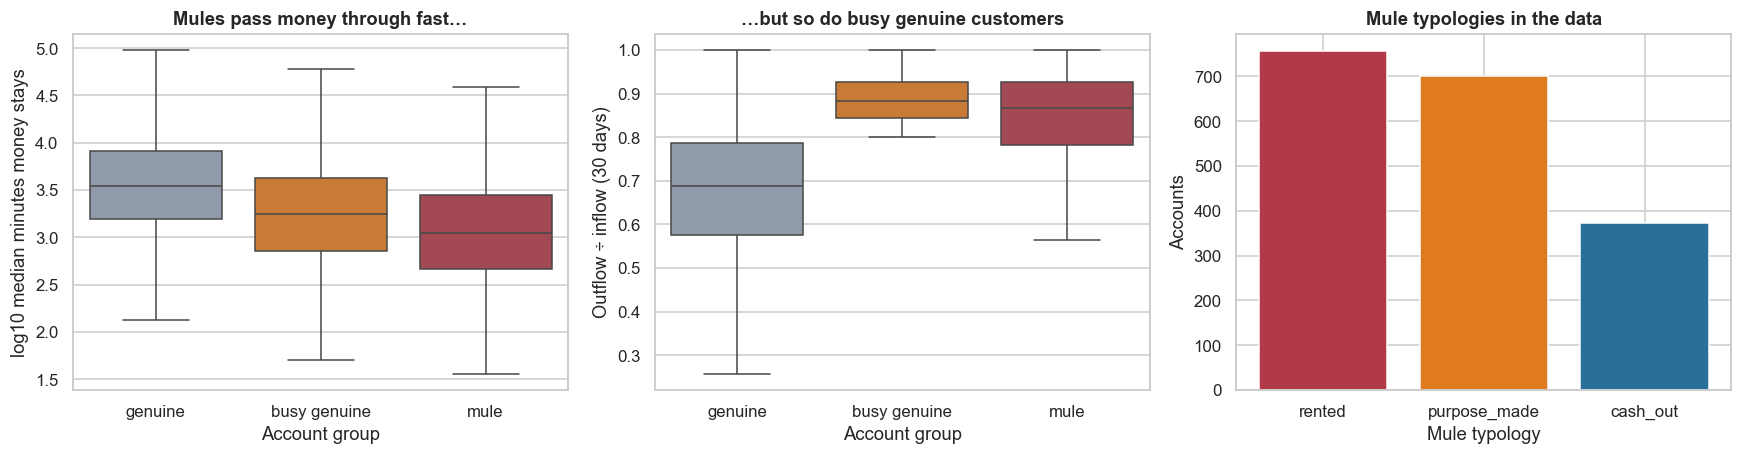

In [7]:
tr = df[df.split == "train"]; va = df[df.split == "validation"]
acc_all_genuine = 1 - va.is_mule.mean()
print(f"The 'accuracy paradox': predicting NO account is a mule is {acc_all_genuine:.2%} accurate on validation, and catches 0 mules.")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
grp = np.where(df.is_mule == 1, "mule", np.where((df.pass_through_ratio > 0.8) & (df.inbound_txn_30d > 20), "busy genuine", "genuine"))
d_ = df.assign(group=grp)
order = ["genuine", "busy genuine", "mule"]; pal = {"genuine": "#8d99ae", "busy genuine": "#e07a1f", "mule": "#b23a48"}
sns.boxplot(data=d_, x="group", y=np.log10(d_.median_dwell_minutes + 1), order=order, palette=pal, hue="group", legend=False, ax=axes[0], showfliers=False)
axes[0].set_xlabel("Account group"); axes[0].set_ylabel("log10 median minutes money stays"); axes[0].set_title("Mules pass money through fast…")
sns.boxplot(data=d_, x="group", y="pass_through_ratio", order=order, palette=pal, hue="group", legend=False, ax=axes[1], showfliers=False)
axes[1].set_xlabel("Account group"); axes[1].set_ylabel("Outflow ÷ inflow (30 days)"); axes[1].set_title("…but so do busy genuine customers")
mt = df[df.is_mule == 1].mule_type.value_counts()
axes[2].bar(mt.index, mt.values, color=["#b23a48", "#e07a1f", "#2a6f97"]); axes[2].set_xlabel("Mule typology"); axes[2].set_ylabel("Accounts"); axes[2].set_title("Mule typologies in the data")
plt.tight_layout(); plt.show()

**Takeaway:** predicting "no mules" is **99.16% accurate and useless**: the accuracy paradox of rare-event problems. Mules hold money for minutes, not days (left), but **busy genuine customers** (traders, gig workers) also have high pass-through ratios (centre). These hard negatives are why simple rules produce so many false alarms, and why we need several signals combined. Purpose-made and rented mules dominate, with cash-out mules the smaller group (right).

## 7. Statistical Analysis (core section)

### 7.1 The baseline rule system, measured properly

**Why first:** every model claim must be against today's system (the documented baseline is ~20% precision / 50% recall). Our AML rule set flags an account if **any** of three red flags fires: (1) ≥ 2 other accounts share its device; (2) dormant-then-suddenly-active with ≥ 8 distinct senders; (3) account < 120 days old with ≥ 8 distinct senders. **Precision** = share of flagged accounts that are mules. **Recall** = share of mules flagged. Both come with **Wilson 95% CIs**.

In [8]:
def rules(d):
    return ((d.accounts_sharing_device >= 2) | ((d.dormant_then_active == 1) & (d.inbound_distinct_senders_30d >= 8))
            | ((d.account_age_days < 120) & (d.inbound_distinct_senders_30d >= 8))).astype(int).values
def pr_ci(flag, y):
    tp = int(((flag == 1) & (y == 1)).sum()); fp = int(((flag == 1) & (y == 0)).sum()); fn = int(((flag == 0) & (y == 1)).sum())
    pl, ph = proportion_confint(tp, max(tp + fp, 1), method="wilson"); rl, rh = proportion_confint(tp, tp + fn, method="wilson")
    return dict(flagged=tp + fp, TP=tp, precision=tp / max(tp + fp, 1), P_lo=pl, P_hi=ph, recall=tp / (tp + fn), R_lo=rl, R_hi=rh)
y_va = va.is_mule.values
rule_va = rules(va)
base = pr_ci(rule_va, y_va)
pd.DataFrame([base], index=["Rule system (validation)"])

,flagged,TP,precision,P_lo,P_hi,recall,R_lo,R_hi
Rule system (validation),1819,242,0.1330,0.1182,0.1494,0.4151,0.3758,0.4555


**Observation:** the rule system flags 1,819 validation accounts but only 242 are mules: **precision 13% (CI 12–15%)** and **recall 42% (CI 38–46%)**. That is close to the documented baseline (~20% / 50%), slightly worse. In practice, **7 of every 8 accounts the team investigates or freezes are innocent**: a cost in investigator time *and* in customer harm.

### 7.2 Which signals differ? Mann–Whitney U (numeric) and chi-square (binary), Holm-corrected

**(a)** Behaviour features are skewed counts, ratios and amounts → **Mann–Whitney U** with rank-biserial r (single-feature AUC = (1 + |r|)/2). Binary flags → **chi-square** with the phi coefficient (Cramér's V for 2×2). **(b)** Train split only. **(e)** Holm across all 39 tests. **(d)** With ~1,250 mules, power to detect r = 0.1 is ≈ 99%, so a *non*-significant feature is genuinely useless.

In [9]:
rows = []
for f in FEATS:
    a_, b_ = tr.loc[tr.is_mule == 1, f], tr.loc[tr.is_mule == 0, f]
    if set(np.unique(tr[f])) <= {0, 1}:
        t = pd.crosstab(tr[f], tr.is_mule); c2, p, _, ex = stats.chi2_contingency(t, correction=False)
        eff = np.sqrt(c2 / len(tr)) * np.sign(a_.mean() - b_.mean()); test = "chi-square (phi)"
    else:
        U, p = stats.mannwhitneyu(a_, b_); eff = 2 * U / (len(a_) * len(b_)) - 1; test = "Mann–Whitney (r_rb)"
    rows.append((f, test, a_.median(), b_.median(), eff, p))
uni = pd.DataFrame(rows, columns=["feature", "test", "median mule", "median genuine", "effect", "p"])
uni["p_holm"] = multipletests(uni.p, method="holm")[1]; uni["|effect|"] = uni.effect.abs()
print(f"Significant after Holm: {(uni.p_holm < 0.05).sum()} of {len(uni)}; not significant: {list(uni.loc[uni.p_holm >= 0.05, 'feature'])}")
uni.sort_values("|effect|", ascending=False).drop(columns="|effect|").round(4).head(20)

Significant after Holm: 36 of 45; not significant: ['noise_feature_1', 'noise_feature_2', 'noise_feature_3', 'noise_feature_4', 'noise_feature_5', 'dwell_missing', 'occupation_retired', 'pincode_risk_tier_low', 'pincode_risk_tier_medium']


,feature,test,median mule,median genuine,effect,p,p_holm
12,pass_through_ratio,Mann–Whitney (r_rb),0.8690,0.7090,0.5657,0.0000,0.0000
18,merchant_spend_share,Mann–Whitney (r_rb),0.3240,0.5010,-0.4919,0.0000,0.0000
13,median_dwell_minutes,Mann–Whitney (r_rb),"1,097.5000","3,378.0000",-0.4670,0.0000,0.0000
30,card_present_txn_30d,Mann–Whitney (r_rb),2.0000,4.0000,-0.4369,0.0000,0.0000
8,distinct_beneficiaries_30d,Mann–Whitney (r_rb),9.0000,5.0000,0.3912,0.0000,0.0000
5,inbound_distinct_senders_30d,Mann–Whitney (r_rb),8.0000,4.0000,0.3881,0.0000,0.0000
15,night_txn_share,Mann–Whitney (r_rb),0.1850,0.1090,0.3869,0.0000,0.0000
27,app_logins_30d,Mann–Whitney (r_rb),21.0000,18.0000,0.3686,0.0000,0.0000
19,bill_payments_30d,Mann–Whitney (r_rb),1.0000,2.0000,-0.3619,0.0000,0.0000
0,account_age_days,Mann–Whitney (r_rb),332.5000,701.0000,-0.3568,0.0000,0.0000


**(c)/(f) Observation:** **36 of 45 features differ significantly after Holm.** The 9 that don't include all **5 pure-noise features** (as they should), the dwell-missing flag, and a few occupation/region dummies, so the screening works. The strongest signals: **pass-through ratio** (r = 0.57; mules pass on 87% of inflow vs 71%), **merchant spend share** (−0.49; mules don't shop), **dwell time** (−0.47; minutes vs days), **card-present transactions** (−0.44), distinct beneficiaries and senders (≈ 0.39) and **account age** (−0.36). No single feature exceeds r ≈ 0.57 (single-feature AUC ≈ 0.78), so the signal is spread across many weak indicators, which is the classic case for an ensemble model.

### 7.3 Redundancy: Spearman correlation clusters

Highly correlated features carry the same information. A real-time system pays twice in compute and gets nothing. We find pairs with **|Spearman ρ| > 0.8** and keep the member with the larger univariate effect.

In [10]:
num = [f for f in FEATS if f in uni.loc[uni.p_holm < 0.05, "feature"].values]
rho = tr[num].corr(method="spearman")
pairs = [(a, b, rho.loc[a, b]) for i, a in enumerate(num) for b in num[i + 1:] if abs(rho.loc[a, b]) > 0.8]
eff_map = uni.set_index("feature").effect.abs()
drop_red = {min((a, b), key=lambda f: eff_map[f]) for a, b, _ in pairs}
print("Redundant pairs (|ρ| > 0.8):"); print(pd.DataFrame(pairs, columns=["feature A", "feature B", "Spearman ρ"]).round(3).to_string(index=False))
screened = [f for f in num if f not in drop_red]
print(f"\nDropped as redundant: {sorted(drop_red)} -> {len(screened)} features remain after screening")

Redundant pairs (|ρ| > 0.8):
      feature A                    feature B  Spearman ρ
inbound_txn_30d inbound_distinct_senders_30d      0.8970
inbound_txn_30d             inbound_count_7d      0.8740

Dropped as redundant: ['inbound_count_7d', 'inbound_txn_30d'] -> 34 features remain after screening


### 7.4 Pruning to 17 features: permutation-importance backward elimination, with a statistical check

**Method (D-8-05):** split train into an inner fit (75%) and an inner check (25%) part. Fit the RF (1:5), rank features by **permutation importance** (the drop in average precision when a feature is shuffled), and repeatedly remove the least important. At each size we record inner-check PR-AUC. We then test **H2** on the 70k validation set: is PR-AUC with 17 features different from PR-AUC with all candidates? We use a **paired bootstrap** of the difference: the same resampled accounts are scored by both models.

In [11]:
def rf(cw={0: 1, 1: 5}, n=150):
    return RandomForestClassifier(n_estimators=n, min_samples_leaf=5, class_weight=cw, n_jobs=-1, random_state=SEED)
fit_i, chk_i = train_test_split(tr, test_size=0.25, stratify=tr.is_mule, random_state=SEED)
imp_s = pd.concat([chk_i[chk_i.is_mule == 1], chk_i[chk_i.is_mule == 0].sample(8000, random_state=SEED)])   # importance sample (ranking only)
current, path = list(screened), []
while True:
    m = rf().fit(fit_i[current], fit_i.is_mule)
    ap = average_precision_score(chk_i.is_mule, m.predict_proba(chk_i[current])[:, 1])
    path.append((len(current), ap, list(current)))
    if len(current) <= 8: break
    pi = permutation_importance(m, imp_s[current], imp_s.is_mule, scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=1)
    imp = pd.Series(pi.importances_mean, index=current).sort_values()
    n_drop = max(1, (len(current) - 17) // 2) if len(current) > 17 else (2 if len(current) > 10 else 1)
    current = [f for f in current if f not in imp.index[:n_drop]]
path_df = pd.DataFrame([(n, a) for n, a, _ in path], columns=["features", "inner PR-AUC"])
F17 = next(c for n, a, c in path if n == 17) if any(n == 17 for n, _, _ in path) else path[1][2]
print("Selected 17 features:", F17)
path_df

Selected 17 features: ['account_age_days', 'devices_linked_30d', 'accounts_sharing_device', 'distinct_beneficiaries_30d', 'pass_through_ratio', 'median_dwell_minutes', 'night_txn_share', 'atm_withdrawal_share', 'merchant_spend_share', 'bill_payments_30d', 'dormant_then_active', 'upi_handle_changes_90d', 'inbound_from_flagged_accounts', 'max_daily_inflow_ratio', 'app_logins_30d', 'card_present_txn_30d', 'occupation_student']


,features,inner PR-AUC
0,34,0.6575
1,26,0.6603
2,22,0.6627
3,20,0.6536
4,19,0.6519
5,18,0.6406
6,17,0.6446
7,15,0.6362
8,13,0.6122
9,11,0.5813


Validation PR-AUC: all 45 features = 0.688 | 17 features = 0.676 | difference -0.012, 95% paired-bootstrap CI [-0.024, -0.001]


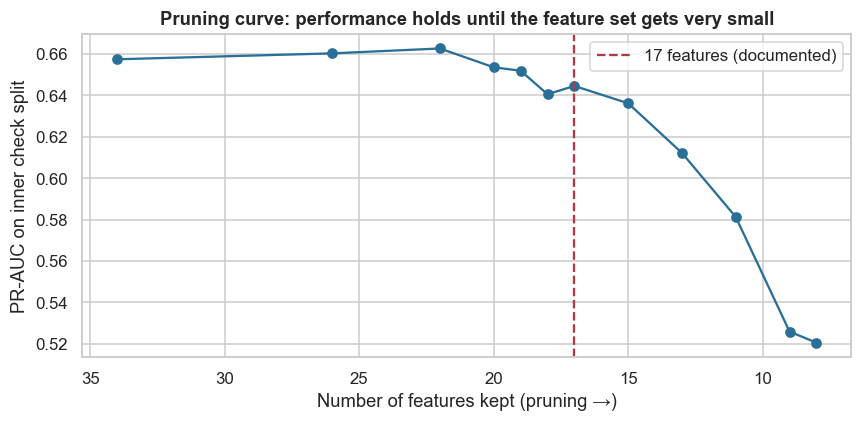

In [12]:
m_all = rf().fit(tr[FEATS], tr.is_mule); m_17 = rf().fit(tr[F17], tr.is_mule)
s_all, s_17 = m_all.predict_proba(va[FEATS])[:, 1], m_17.predict_proba(va[F17])[:, 1]
diffs = []
for _ in range(500):
    i = RNG.integers(0, len(y_va), len(y_va)); diffs.append(average_precision_score(y_va[i], s_17[i]) - average_precision_score(y_va[i], s_all[i]))
ap_all, ap_17 = average_precision_score(y_va, s_all), average_precision_score(y_va, s_17)
print(f"Validation PR-AUC: all {len(FEATS)} features = {ap_all:.3f} | 17 features = {ap_17:.3f} | difference {ap_17 - ap_all:+.3f}, "
      f"95% paired-bootstrap CI [{np.percentile(diffs, 2.5):+.3f}, {np.percentile(diffs, 97.5):+.3f}]")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(path_df.features, path_df["inner PR-AUC"], "o-", color="#2a6f97"); ax.axvline(17, ls="--", color="#b23a48", label="17 features (documented)")
ax.invert_xaxis(); ax.set_xlabel("Number of features kept (pruning →)"); ax.set_ylabel("PR-AUC on inner check split")
ax.set_title("Pruning curve: performance holds until the feature set gets very small"); ax.legend(); plt.tight_layout(); plt.show()

**Takeaway / H2:** - The pruning curve is **flat from 34 down to about 17 features** (inner PR-AUC 0.66 → 0.64), then falls steeply below 13 (0.52 at 8 features). **17 sits at the knee of the curve**, consistent with the documented choice.
- **H2 test:** on the 70k hold-out, 17 features give PR-AUC **0.676** vs **0.688** with all 45. The difference is **−0.012 (95% CI −0.024 to −0.001)**, so it is *statistically* significant but small (≈ 2% relative). **Business reading:** we give up about 2% of ranking quality to compute 17 instead of 45 signals in real time, which halves the feature-store load and removes fragile features. If the business pre-defines an equivalence margin of ±0.03 PR-AUC, the whole CI sits inside it, so the pruned model is **practically equivalent**.

### 7.5 Algorithm and class-weight comparison on the 70,000-account hold-out

Candidates, all on the **same 17 features**, with sensible defaults and no tuning beyond the class weight the case documents (D-8-06):
- **Logistic regression** (balanced weights), the interpretable baseline;
- **RF Regressor** on the 0/1 label (documented as tried);
- **Gradient boosting** (HistGradientBoosting; documented as tried);
- **RF Classifier unweighted**;
- **RF Classifier 1:5 (documented choice)**;
- **RF Classifier "balanced"** (weight ≈ 1:120, the inverse class frequency).

**Metric:** PR-AUC with bootstrap 95% CIs, plus a paired bootstrap of each model's difference vs RF 1:5. ROC-AUC is shown for contrast.

In [13]:
models = {
    "Logistic (balanced)": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000)),
    "RF Regressor": RandomForestRegressor(n_estimators=150, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
    "RF unweighted": rf(cw=None), "RF 1:5 (documented)": rf(), "RF balanced (≈1:120)": rf(cw="balanced"),
}
S = {}
for n, m in models.items():
    m.fit(tr[F17], tr.is_mule)
    S[n] = m.predict(va[F17]) if n == "RF Regressor" else m.predict_proba(va[F17])[:, 1]
idx_b = [RNG.integers(0, len(y_va), len(y_va)) for _ in range(400)]
ref = S["RF 1:5 (documented)"]
rows = []
for n, s in S.items():
    aps = np.array([average_precision_score(y_va[i], s[i]) for i in idx_b]); d_ = np.array([average_precision_score(y_va[i], s[i]) - average_precision_score(y_va[i], ref[i]) for i in idx_b])
    rows.append((n, roc_auc_score(y_va, s), average_precision_score(y_va, s), *np.percentile(aps, [2.5, 97.5]), np.mean(d_), *np.percentile(d_, [2.5, 97.5])))
cmpm = pd.DataFrame(rows, columns=["model", "ROC-AUC", "PR-AUC", "PR lo", "PR hi", "Δ vs RF 1:5", "Δ lo", "Δ hi"]).set_index("model")
cmpm["significantly different from RF 1:5"] = (cmpm["Δ lo"] > 0) | (cmpm["Δ hi"] < 0)
cmpm.round(3)

,ROC-AUC,PR-AUC,PR lo,PR hi,Δ vs RF 1:5,Δ lo,Δ hi,significantly different from RF 1:5
model,,,,,,,,
Logistic (balanced),0.9490,0.6070,0.5700,0.6470,-0.0680,-0.1000,-0.0380,True
RF Regressor,0.9460,0.6040,0.5660,0.6400,-0.0710,-0.0890,-0.0580,True
Gradient boosting,0.9560,0.5600,0.5200,0.6000,-0.1150,-0.1420,-0.0900,True
RF unweighted,0.9550,0.6510,0.6140,0.6850,-0.0250,-0.0350,-0.0150,True
RF 1:5 (documented),0.9600,0.6760,0.6410,0.7090,0.0000,0.0000,0.0000,False
RF balanced (≈1:120),0.9610,0.6350,0.5990,0.6710,-0.0400,-0.0630,-0.0200,True


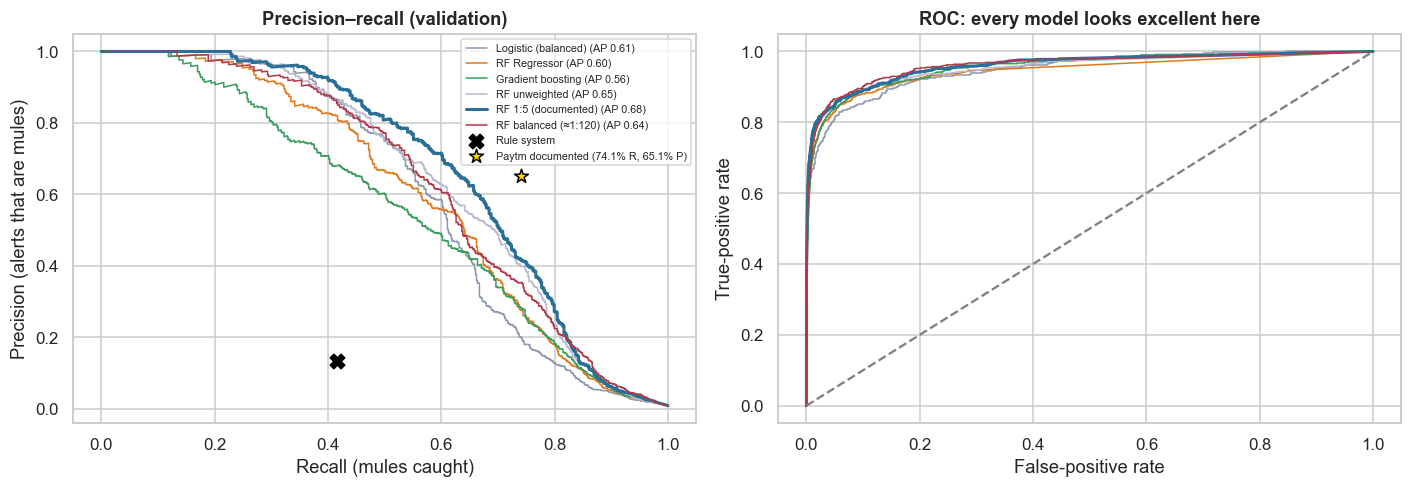

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
cl = dict(zip(S, ["#8d99ae", "#e07a1f", "#3a9d5d", "#b8b8d1", "#2a6f97", "#b23a48"]))
for n, s in S.items():
    p_, r_, _ = precision_recall_curve(y_va, s); axes[0].plot(r_, p_, color=cl[n], lw=2 if "documented" in n else 1, label=f"{n} (AP {average_precision_score(y_va, s):.2f})")
    f_, t_, _ = roc_curve(y_va, s); axes[1].plot(f_, t_, color=cl[n], lw=2 if "documented" in n else 1)
axes[0].scatter([base["recall"]], [base["precision"]], s=90, color="black", marker="X", zorder=5, label="Rule system")
axes[0].scatter([0.741], [0.651], s=90, color="gold", edgecolor="black", marker="*", zorder=5, label="Paytm documented (74.1% R, 65.1% P)")
axes[0].set_xlabel("Recall (mules caught)"); axes[0].set_ylabel("Precision (alerts that are mules)"); axes[0].set_title("Precision–recall (validation)"); axes[0].legend(fontsize=7)
axes[1].plot([0, 1], [0, 1], "--", color="grey"); axes[1].set_xlabel("False-positive rate"); axes[1].set_ylabel("True-positive rate"); axes[1].set_title("ROC: every model looks excellent here")
plt.tight_layout(); plt.show()

**(c)/(f) Observation and takeaway:** - **RF 1:5 (documented) has the best PR-AUC: 0.676** (CI 0.64–0.71). **Every alternative is significantly worse** in a paired bootstrap: RF unweighted −0.025, RF "balanced" (≈ 1:120) −0.040, logistic −0.068, RF regressor −0.071, gradient boosting −0.115 (with untuned defaults it over-focuses on easy cases).
- **Why 1:5 beats "balanced":** heavy weighting (1:120) pushes the forest to over-predict mules everywhere, which adds noise among the top-ranked accounts. Moderate weighting improves recall in the useful high-precision region without flooding it. This matches Paytm's documented choice of a moderate 1:5.
- **ROC curves are nearly indistinguishable** (AUC 0.95–0.96 for all), while the PR curves separate clearly. For rare events, the PR curve is the decision chart.
- On the PR chart, the **rule system sits far below every model curve**, and the documented Paytm operating point (65% P, 74% R) lies close to our RF 1:5 curve.

### 7.6 From the PR curve to action tiers, and the head-to-head with the rules

**Threshold selection (on the inner check split, not the validation set):**
- **Block tier:** the lowest threshold whose precision is ≥ 85%. Freezing a genuine account is serious, so this tier must be very precise.
- **Investigate / limit tier:** from the block threshold down to the threshold that maximises F1 overall.
- Below that: **watch** (no action, monitoring only).

On validation we then compare the overall alert set (block + investigate) with the rule system: **two-proportion Z-test on precision**, **McNemar on which mules are caught**, and Wilson CIs.

In [15]:
rf17 = models["RF 1:5 (documented)"]
s_chk = rf(n=150).fit(fit_i[F17], fit_i.is_mule).predict_proba(chk_i[F17])[:, 1]
p_c, r_c, t_c = precision_recall_curve(chk_i.is_mule, s_chk)
f1 = 2 * p_c[:-1] * r_c[:-1] / (p_c[:-1] + r_c[:-1] + 1e-12)
T_INV = t_c[np.argmax(f1)]
ok = np.where(p_c[:-1] >= 0.85)[0]; T_BLOCK = t_c[ok[0]] if len(ok) else t_c[-1]
s_va = S["RF 1:5 (documented)"]
tier = np.where(s_va >= T_BLOCK, "block", np.where(s_va >= T_INV, "investigate / limit", "watch"))
tiers = []
for t_ in ["block", "investigate / limit", "watch"]:
    m_ = tier == t_; tp = int(y_va[m_].sum()); lo, hi = proportion_confint(tp, max(m_.sum(), 1), method="wilson")
    tiers.append((t_, int(m_.sum()), tp, tp / max(m_.sum(), 1), lo, hi, tp / y_va.sum()))
tiers = pd.DataFrame(tiers, columns=["tier", "accounts", "mules", "precision", "P lo", "P hi", "share of all mules"]).set_index("tier")
print(f"Thresholds chosen on inner check split: block ≥ {T_BLOCK:.3f}, investigate ≥ {T_INV:.3f}")
model_flag = (s_va >= T_INV).astype(int)
mod = pr_ci(model_flag, y_va)
z, p_prec = proportions_ztest([mod["TP"], base["TP"]], [mod["flagged"], base["flagged"]])
both = np.array([[np.sum((model_flag == 1) & (rule_va == 1) & (y_va == 1)), np.sum((model_flag == 1) & (rule_va == 0) & (y_va == 1))],
                 [np.sum((model_flag == 0) & (rule_va == 1) & (y_va == 1)), np.sum((model_flag == 0) & (rule_va == 0) & (y_va == 1))]])
mc = mcnemar(both, exact=False, correction=True)
head = pd.DataFrame([base, mod], index=["Rule system", "RF 1:5 (block + investigate)"])
print(f"Precision model vs rules: Z = {z:.1f}, p = {p_prec:.2g} | mules caught [[both, model only], [rules only, neither]] = {both.tolist()}, McNemar p = {mc.pvalue:.2g}")
display(tiers.round(3)); head.round(3)

Thresholds chosen on inner check split: block ≥ 0.523, investigate ≥ 0.272
Precision model vs rules: Z = 24.0, p = 1.5e-127 | mules caught [[both, model only], [rules only, neither]] = [[192, 189], [50, 152]], McNemar p = 4.4e-19


,accounts,mules,precision,P lo,P hi,share of all mules
tier,,,,,,
block,255,234,0.9180,0.8770,0.9460,0.4010
investigate / limit,356,147,0.4130,0.3630,0.4650,0.2520
watch,69128,202,0.0030,0.0030,0.0030,0.3460


,flagged,TP,precision,P_lo,P_hi,recall,R_lo,R_hi
Rule system,1819,242,0.1330,0.1180,0.1490,0.4150,0.3760,0.4560
RF 1:5 (block + investigate),611,381,0.6240,0.5840,0.6610,0.6540,0.6140,0.6910


**(c)/(f) Observation:** - **Block tier** (score ≥ 0.52): 255 accounts, **234 mules: precision 92% (CI 88–95%)**, ✅ above the 85% bar, holding **40% of all mules**.
- **Investigate / limit tier** (0.27–0.52): 356 accounts, precision 41%, another 25% of mules. Below that, "watch" holds 35% of mules at 0.3% precision, so they are not worth working.
- **Overall alerts (block + investigate): precision 62% (CI 58–66%), recall 65% (CI 61–69%)** vs the rules' 13% / 42%. Precision: Z = 24, p ≈ 10⁻¹²⁷. Paired detection: the model catches 189 mules the rules miss, while the rules catch 50 the model misses (McNemar p ≈ 10⁻¹⁹).
- **Decision rule met:** precision and recall both significantly better, and block-tier precision ≥ 85%.

### 7.7 Calibration: class weights distort probabilities

**Why it matters:** with 1:5 weighting, the forest is trained as if mules were 5× more common, so its raw "probability" overstates risk. That is harmless for *ranking*, but wrong for expected-loss provisioning or capacity planning ("how many real mules will this tier contain?"). We compare predicted and observed rates by decile, compute the **Brier score**, and recalibrate with **isotonic regression** (sklearn `CalibratedClassifierCV`, 3-fold on train).

Brier score: raw RF 1:5 = 0.00469 | isotonic-calibrated = 0.00420 | mean predicted 0.0144 / 0.0083 vs observed 0.0084
PR-AUC after calibration: 0.674 (ranking essentially unchanged)


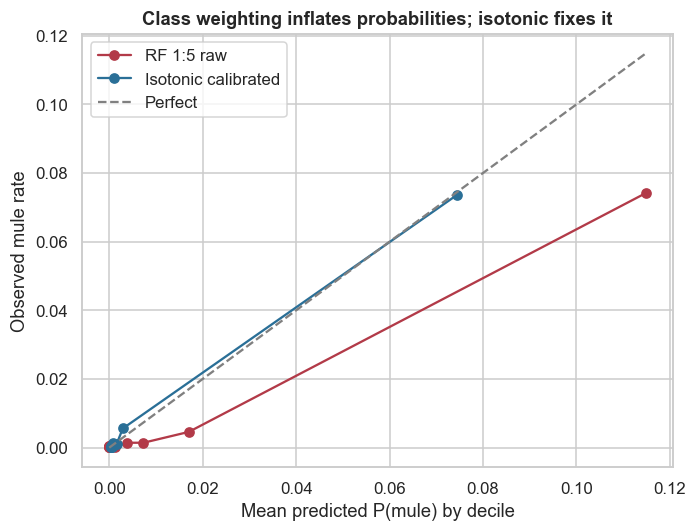

In [16]:
cal = CalibratedClassifierCV(rf(), method="isotonic", cv=3).fit(tr[F17], tr.is_mule)
s_cal = cal.predict_proba(va[F17])[:, 1]
def rel_table(s, y):
    d = pd.DataFrame({"s": s, "y": y}); d["bin"] = pd.qcut(d.s.rank(method="first"), 10, labels=False)
    return d.groupby("bin").agg(pred=("s", "mean"), obs=("y", "mean"), n=("y", "size"))
rt_raw, rt_cal = rel_table(s_va, y_va), rel_table(s_cal, y_va)
print(f"Brier score: raw RF 1:5 = {brier_score_loss(y_va, s_va):.5f} | isotonic-calibrated = {brier_score_loss(y_va, s_cal):.5f} | "
      f"mean predicted {s_va.mean():.4f} / {s_cal.mean():.4f} vs observed {y_va.mean():.4f}")
print(f"PR-AUC after calibration: {average_precision_score(y_va, s_cal):.3f} (ranking essentially unchanged)")
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(rt_raw.pred, rt_raw.obs, "o-", color="#b23a48", label="RF 1:5 raw"); ax.plot(rt_cal.pred, rt_cal.obs, "o-", color="#2a6f97", label="Isotonic calibrated")
mx = max(rt_raw.pred.max(), rt_cal.pred.max()); ax.plot([0, mx], [0, mx], "--", color="grey", label="Perfect")
ax.set_xlabel("Mean predicted P(mule) by decile"); ax.set_ylabel("Observed mule rate"); ax.set_title("Class weighting inflates probabilities; isotonic fixes it"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** the 1:5 weighting makes the raw forest **over-state risk by about 70%** (mean predicted 1.44% vs observed 0.84%). Isotonic calibration brings it to 0.83%, improves the Brier score (0.00469 → 0.00420), and leaves ranking untouched (PR-AUC 0.674). **Use the calibrated score whenever the number itself matters**: expected mules per tier, staffing, provisioning. The raw score is fine for ranking.

### 7.8 Who does the model miss? Recall by typology and mule intensity

In [17]:
vm = va[va.is_mule == 1].assign(caught=(s_va[va.is_mule.values == 1] >= T_INV).astype(int))
by_type = vm.groupby("mule_type").caught.agg(["sum", "size", "mean"])
lo, hi = proportion_confint(by_type["sum"], by_type["size"], method="wilson"); by_type["CI low"], by_type["CI high"] = lo, hi
c2, p_t, dof_t, ex_t = stats.chi2_contingency(pd.crosstab(vm.mule_type, vm.caught))
print(f"Recall differs by typology? chi2 = {c2:.1f}, dof = {dof_t}, p = {p_t:.2g}, min expected = {ex_t.min():.1f}")
vm["inbound_band"] = pd.qcut(vm.inbound_txn_30d.rank(method="first"), 4, labels=["lightest 25%", "Q2", "Q3", "busiest 25%"])
print("Recall by mule activity quartile:", vm.groupby("inbound_band", observed=True).caught.mean().round(3).to_dict())
by_type.rename(columns={"sum": "caught", "size": "mules", "mean": "recall"}).round(3)

Recall differs by typology? chi2 = 27.3, dof = 2, p = 1.2e-06, min expected = 37.8
Recall by mule activity quartile: {'lightest 25%': 0.562, 'Q2': 0.589, 'Q3': 0.697, 'busiest 25%': 0.767}


,caught,mules,recall,CI low,CI high
mule_type,,,,,
cash_out,61,109,0.5600,0.4660,0.6490
purpose_made,185,238,0.7770,0.7200,0.8260
rented,135,236,0.5720,0.5080,0.6340


**Observation:** recall differs strongly by typology (χ² = 27, p ≈ 10⁻⁶). **Purpose-made mules: 78%** (new accounts, shared devices, which are easy to spot). **Rented mules: 57%** and **cash-out mules: 56%**: aged genuine-looking accounts and ATM-heavy patterns are harder. Recall also rises with mule activity (56% for the lightest quarter vs 77% for the busiest). **The model is weakest on quiet, rented accounts**, exactly where network features (shared beneficiaries, recruitment links; Cases 9–10) should help next.

## 8. ML Section — what the 17-feature forest relies on

The model was chosen in 7.5. Here we explain it with **permutation importance** on the validation set (the drop in PR-AUC when a feature is shuffled). This is how investigators get a "reason list" for each alert.

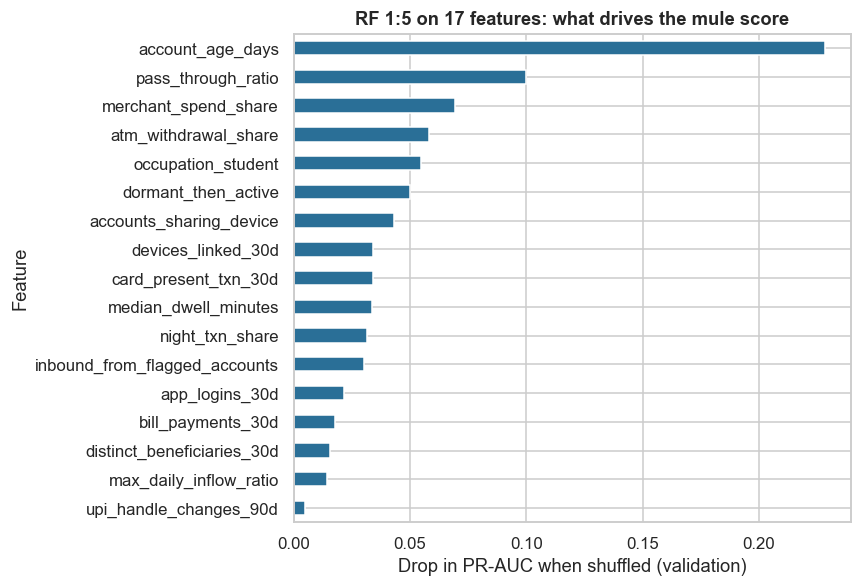

In [18]:
pi = permutation_importance(rf17, va[F17], y_va, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=F17).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5)); imp.plot(kind="barh", color="#2a6f97", ax=ax)
ax.set_xlabel("Drop in PR-AUC when shuffled (validation)"); ax.set_ylabel("Feature"); ax.set_title("RF 1:5 on 17 features: what drives the mule score")
plt.tight_layout(); plt.show()

**Takeaway:** **account age** is by far the strongest driver, followed by **pass-through ratio**, **merchant spending share** (mules don't shop), **ATM withdrawal share** (cash-out), the **student** flag and **dormant-then-active**. Each maps to a documented mule typology, so investigators get a readable reason list ("new account, passes 90% on within an hour, no shopping"). Noise features are gone, and every retained signal carries real information.

## 9. Business Translation — investigator capacity and ₹ fraud proceeds intercepted

**Logic, per 10 lakh accounts per month (scaled from validation):**
1. Alerts per tier, and the true mules in each.
2. **₹ intercepted:** a mule caught early cannot receive the rest of its fraud inflow. We assume half of a mule's next month's inflow is fraud proceeds that would otherwise be lost, and that detection blocks that half (assumption: 50%).
3. **Costs:** investigation ₹400 per investigate-tier alert; **wrongly frozen genuine account** ₹2,000 (support, complaint, churn risk, regulatory exposure); wrongly limited account ₹300.
4. Compare the rules and the model, and check the **investigator capacity** (assumption: 25 investigators × 20 cases/day × 22 days = 11,000 cases a month).

In [19]:
scale = 1_000_000 / len(va)
mule_inflow = va.total_inflow_30d.values * 0.5             # assumed fraud-proceeds share of next month's inflow
def econ(flag_block, flag_inv, label):
    blk, inv = flag_block.astype(bool), flag_inv.astype(bool) & ~flag_block.astype(bool)
    intercepted = mule_inflow[(blk | inv) & (y_va == 1)].sum() * scale
    cost = (400 * inv.sum() + 2000 * (blk & (y_va == 0)).sum() + 300 * (inv & (y_va == 0)).sum()) * scale
    return (label, (blk.sum()) * scale, inv.sum() * scale, ((blk | inv) & (y_va == 1)).sum() * scale, ((blk | inv) & (y_va == 0)).sum() * scale,
            intercepted / 1e7, cost / 1e7, (intercepted - cost) / 1e7)
ec = pd.DataFrame([econ(np.zeros_like(rule_va), rule_va, "Rule system (all to investigation)"),
                   econ((s_va >= T_BLOCK).astype(int), (s_va >= T_INV).astype(int), "RF 1:5 tiers")],
                  columns=["system", "blocks / month", "investigations / month", "mules stopped", "genuine accounts actioned", "₹ crore intercepted", "₹ crore cost", "₹ crore net"]).set_index("system")
CAP = 25 * 20 * 22
print(f"Investigator capacity ≈ {CAP:,} cases/month")
ec.round(2)

Investigator capacity ≈ 11,000 cases/month


,blocks / month,investigations / month,mules stopped,genuine accounts actioned,₹ crore intercepted,₹ crore cost,₹ crore net
system,,,,,,,
Rule system (all to investigation),0.0000,"26,082.9700","3,470.0800","22,612.8900",31.4600,1.7200,29.7400
RF 1:5 tiers,"3,656.4900","5,104.7500","5,463.2300","3,298.0100",41.1600,0.3500,40.8100


In [20]:
sens = []
for lab, share, fz in [("Worst (25% of inflow is fraud, ₹4,000 per wrong freeze)", 0.25, 4000), ("Base (50%, ₹2,000)", 0.5, 2000), ("Best (75%, ₹1,000)", 0.75, 1000)]:
    out = []
    for blk, inv in [(np.zeros_like(rule_va), rule_va), ((s_va >= T_BLOCK).astype(int), (s_va >= T_INV).astype(int))]:
        b_, i_ = blk.astype(bool), inv.astype(bool) & ~blk.astype(bool)
        gain = (va.total_inflow_30d.values * share)[(b_ | i_) & (y_va == 1)].sum()
        cost = 400 * i_.sum() + fz * (b_ & (y_va == 0)).sum() + 300 * (i_ & (y_va == 0)).sum()
        out.append((gain - cost) * scale / 1e7)
    sens.append((lab, *out, out[1] - out[0]))
pd.DataFrame(sens, columns=["scenario", "rules net ₹ cr/month", "model net ₹ cr/month", "model advantage ₹ cr/month"]).set_index("scenario").round(2)

,rules net ₹ cr/month,model net ₹ cr/month,model advantage ₹ cr/month
scenario,,,
"Worst (25% of inflow is fraud, ₹4,000 per wrong freeze)",14.0100,20.1700,6.1600
"Base (50%, ₹2,000)",29.7400,40.8100,11.0700
"Best (75%, ₹1,000)",45.4700,61.4200,15.9500


**Business reading:** - **Per 10 lakh accounts a month:** the rules generate **≈ 26,100 investigations**, more than double the ≈ 11,000-case team capacity, so in reality most alerts go un-worked. They catch ≈ 3,500 mules and action ≈ 22,600 genuine customers.
- **The model** auto-blocks ≈ 3,700 accounts (92% precise) and sends ≈ 5,100 for investigation, **inside capacity**. It catches **≈ 5,500 mules (+57%)** and actions only **≈ 3,300 genuine customers (−85%)**.
- **₹:** ≈ ₹41 crore a month net vs ₹30 crore for the rules, an **advantage of ≈ ₹11 crore a month** (range ₹6–16 crore depending on the fraud share of mule inflows and the cost of a wrong freeze).
- The ₹ figures depend on our assumptions (50% of a mule's next-month inflow is fraud proceeds; ₹2,000 per wrongful freeze). The *operational* gains (fewer investigations, fewer innocent customers frozen, more mules caught) hold under every scenario.

## 10. Recommendation and Decision

**Decision against the pre-registered rule:** precision and recall both significantly beat the rules ✅; block-tier precision 92% ≥ 85% ✅. **Deploy.**

**I recommend:**
1. **Deploy RF 1:5 on the 17 features** in the real-time risk engine (documented: Maquette + rule engine), with **three tiers**: block (≥ 0.52), investigate/limit (0.27–0.52), watch.
2. **Keep the rules as a parallel safety net for 1 quarter**: accounts flagged only by rules go to a low-priority queue, so nothing the old system caught is silently lost.
3. **Use the isotonic-calibrated score** for capacity planning and reporting; recalibrate monthly.
4. **Customer protection:** blocked customers get a notice and a 48-hour review path. Track reinstatement and false-freeze rates by occupation (students, traders) and region.
5. **Next model iteration:** add network features to lift recall on rented and cash-out mules (currently 56–57%).

**KPIs:** precision and recall on investigated cases (monthly, Wilson CIs); block-tier precision (target ≥ 85%); recall by typology; investigations vs capacity; genuine accounts actioned per 10,000; reinstatement rate; ₹ intercepted; score drift (PSI).

## 11. Risks, Limitations and Next Steps

- **Synthetic data:** typologies and intensities are ours. Real mules evolve quickly (new rental schemes, mule recruitment via job scams), so retrain quarterly and watch recall by typology.
- **Label quality:** "mule" labels come from investigations and law-enforcement requests, so they are biased towards the patterns investigators already look for. Feedback loops can blind the model to new typologies. Keep a small random-audit stream of un-flagged accounts.
- **Fairness and customer harm:** students and small traders are over-represented among false positives. Freezes must follow RBI's customer-protection norms (notice, quick review, a reinstatement SLA). Track false-freeze rates by occupation and region.
- **Probability use:** use the **isotonic-calibrated** score for expected-loss and capacity planning, and the raw score only for ranking.
- **Next steps:** (1) add network features (accounts sharing beneficiaries/devices; see Cases 9–10); (2) a quarterly pruning refresh with the same bootstrap check; (3) consortium data (RBIH MuleHunter, Case 9) to see mules that use several banks.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Precision / recall | TP/(TP + FP), TP/(TP + FN); Wilson CIs |
| Average precision (PR-AUC) | Σ (R_k − R_{k−1}) P_k |
| F1 | 2PR/(P + R) |
| Class weight w | each mule counts as w genuine accounts in the loss/impurity |
| Brier score | mean (p̂ − y)² |
| Paired bootstrap Δ | resample accounts once, score both models, take the AP difference; percentile CI |
| Permutation importance | metric(original) − metric(feature shuffled) |

| Term | Meaning |
|---|---|
| Mule account | An account used to receive and move criminal money. |
| Imbalanced classification | One class is very rare (here < 1%), so accuracy is meaningless. |
| Class weighting | Making each rare-class example count more during training. |
| PR curve | Precision vs recall as the alert threshold moves; the key chart for rare events. |
| Tiered response | Different actions for different score bands (block / investigate / watch). |
| Calibration | Whether a "10% risk" really means 10 in 100. |
| Hard negatives | Genuine customers who look like the rare class (busy traders here). |